# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [2]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": int(df.duplicated().sum()),
    "rating_missing_pct": round(df["rating"].isna().mean() * 100, 1),
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13987,
 'columns': 15,
 'duplicate_rows': 70,
 'rating_missing_pct': np.float64(27.6),
 'order_id_unique_pct': 99.5}

mean = ₹465 | median = ₹358 | skew = 13.2


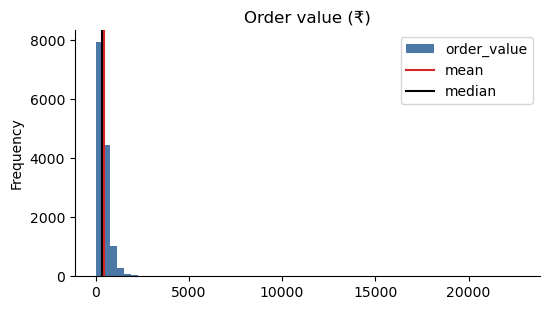

In [3]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()      # TODO: mean order_value
aov_median = df["order_value"].median()    # TODO: median order_value
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [4]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

city
Bengaluru    21.1
Hyderabad    45.0
Pune         20.6
Name: rating, dtype: float64

**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

*Your answer:*

(a) Insight 2 is the one affected. The ₹465 figure is the correct mean (₹465 on the de-duplicated table), but order value is very right-skewed (skew ≈ 13). A few very large baskets pull the mean up, so the median is only ₹358. The "average" overstates a typical order by about ₹107 (≈30%). The profile also found 70 fully duplicated rows, so any figure computed before de-duplication is slightly off too. Rewrite: "A typical FreshKart order is about ₹358 (median, Jan–Sep). The mean is higher (₹465) because a small number of very large orders pull it up."

(b) 27.6% of ratings are missing overall, but the gaps are not spread evenly: Hyderabad is missing 45% of ratings, against about 21% in Bengaluru and Pune. So the data is not missing at random. The r = −0.32 in insight 6 is computed only on rated orders, so Hyderabad is under-represented, and the customers who skip rating may differ systematically from those who rate (for example, unhappy customers after a late delivery may stay silent). That selection bias can push the correlation in either direction, so it should be reported as "among rated orders", with the missing-rate shown next to it, and it should not be generalised to all customers or used to compare cities.

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

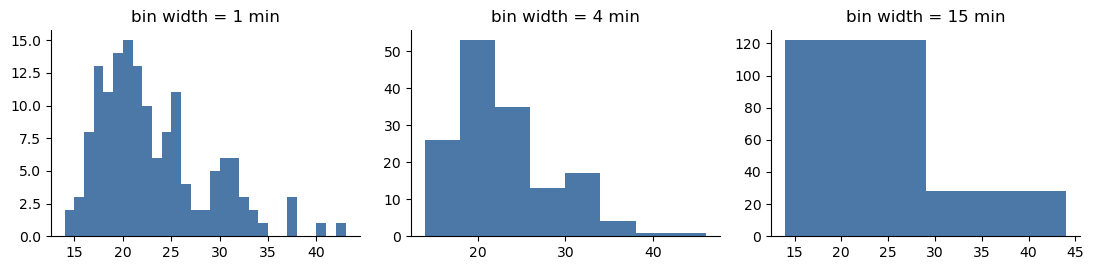

multimodal_supported = False | best_bin_width = 4


In [5]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False    # TODO: True or False
best_bin_width = 4          # TODO: 1, 4 or 15
print(f"multimodal_supported = {multimodal_supported} | best_bin_width = {best_bin_width}")

**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

*Your answer:*

Re-plot the same data with several bin widths (and ideally a density/KDE or a principled rule such as Freedman–Diaconis), and accept the shape only if it holds across reasonable settings. Here the "three peaks" exist only at 1-minute bins on 150 orders (sampling noise). At 4-minute bins the distribution is a single right-skewed hump peaking around 18–22 min, and at 15-minute bins all detail is smoothed away, so multimodality is not supported.

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


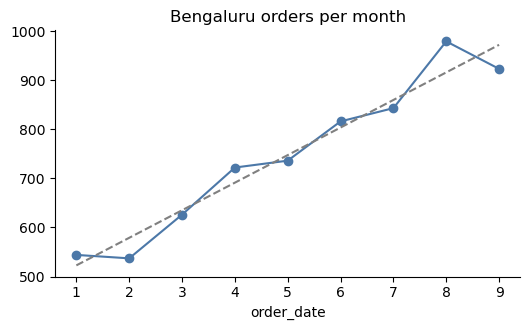

In [6]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]   # TODO: slope of a straight-line fit of monthly orders on month (hint: np.polyfit(months, monthly.values, 1)[0])
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


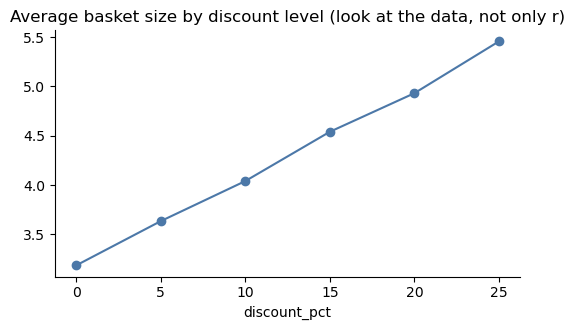

In [7]:
r_disc_items = df["discount_pct"].corr(df["items"])    # TODO: Pearson r between discount_pct and items

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = bool(np.isclose(r_minutes, r_hours))   # r is unit-free     # TODO: True/False - is r the same after rescaling? (hint: np.isclose)

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [8]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(num_cols) * (len(num_cols) - 1) // 2      # C(7,2) = 21
expected_false = n_pairs * 0.05
bonferroni = 0.05 / n_pairs

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.378,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.066,5.802888e-15,True
14,discount_pct,loyalty_points,-0.022,8.317915e-03,False


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?

*Your answer:*
(a) Yes, reasonably. The fitted slope is +56.2 orders/month, and the Mann–Kendall-style test gives Kendall τ = 0.89, p ≈ 0.0002, so the upward direction is not noise: monthly orders went from 544 in January to 923 in September. But 9 points is a small sample. "Steadily" is too strong, because the series is not smooth: Feb is flat, and September (923) dropped from August (979). I would show the monthly line chart with the actual points, the fitted line, the slope with an uncertainty range, and an annotation of the September dip. The number should not be used to extrapolate.

(b) The chart supports "move together": mean basket size rises almost linearly from about 3.2 items at 0% discount to about 5.5 items at 25%, and r = 0.38 is computed correctly. (r is also identical in minutes or hours: correlation is unit-free.) But this is observational data, so it cannot say discounts cause bigger baskets. The causation could run the other way (bigger baskets may unlock higher discount tiers), or a third factor (promo days, loyal or bulk-buying customers) could drive both. Showing causation would need an experiment, such as an A/B test of discount levels.

(c) With 21 pairs tested at α = 0.05, we expect about 1.05 false positives even if nothing were real. Bonferroni threshold = 0.05/21 ≈ 0.0024. The most likely false alarm is discount_pct ~ loyalty_points (r = −0.022, p ≈ 0.008). Reason 1: it fails the Bonferroni correction (0.008 > 0.0024), so it is exactly the kind of chance hit that multiple testing produces. Reason 2: the effect size is negligible: r = −0.022 explains about 0.05% of variance, and it only reaches p < 0.05 because n ≈ 14,000. There is also no clear business mechanism linking them. (order_value ~ discount_pct, r = 0.066, survives Bonferroni but is also too tiny to matter in practice.) The real findings are large and plausible: distance_km ~ delivery_minutes (r = 0.75), items ~ discount_pct and order_value ~ items.

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

C:\Users\Shreya C Rao\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


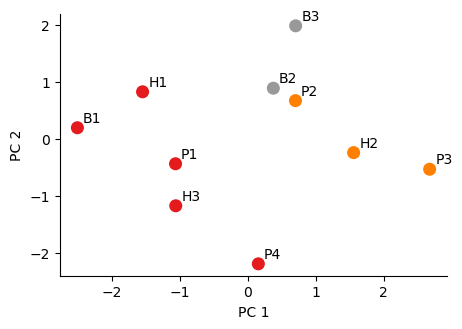

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,8.29,0.92,0.35
H1,0,4.99,0.91,0.35
P1,0,4.76,0.90,0.37
H3,0,4.30,0.91,0.39
P4,0,4.34,0.88,0.41
H2,1,5.24,0.89,0.45
P3,1,5.25,0.88,0.48
P2,1,4.39,0.91,0.42
B2,2,8.90,0.90,0.45


In [10]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

*Your answer:*
With 10 points and 5 features, k-means will always return 3 groups, even when no real structure exists, and the groups can rest on just 2–4 stores each. Here the result is fragile: the silhouette score is low (≈ 0.21 for k = 3, and k = 2 scores slightly higher), and changing random_state reshuffles which stores end up together. The 2-D PCA plot also shows only about 69% of the variance. The clusters also mix in a data artefact: H2's orders_per_active_day and on_time are distorted by its missing September weeks (Part 4). Before naming the segments, I would check: (1) stability, by re-running with different seeds and dropping one store at a time (bootstrap); (2) separation, using silhouette scores for k = 2–4; and (3) interpretability, by looking at the raw feature values per segment (the table above) to see whether each group differs in a way a manager would recognise, such as the high-volume Bengaluru stores. Groups that pass those checks still need a domain expert to confirm they mean something operationally.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [11]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = (hyd_month[9] - hyd_month[8]) / hyd_month[8] * 100     # TODO: % change in Hyderabad orders from August (month 8) to September (month 9)
first_test = 'B'     # TODO: which hypothesis is the cheapest to rule out first? 'A', 'B', 'C' or 'D'

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -28.4% | cheapest test first: B


In [12]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime[9] - ontime[8]   # TODO: on-time % in September minus on-time % in August
culprit_store = 'H2'       # TODO: which store ('H1', 'H2' or 'H3') has a gap in its weekly rows?

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,28,36
2026-09-13,33,0,21
2026-09-20,43,0,38
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

*Your answer:*

Hypothesis B (data problem) is supported: store H2 has zero rows in the weeks ending 13 and 20 September and only partial weeks around them (51 Sep rows vs about 157 in Aug), while A (service got worse) is ruled out: Hyderabad on-time was 89.0% in Aug and 88.7% in Sep (−0.3 points, within normal monthly variation). C (discounts cut) is also ruled out (mean discount 9.35% in Aug vs 9.49% in Sep), and D cannot be tested without competitor or customer-level data.

Corrected insight 4: "Hyderabad's reported 28% drop from August to September is mostly a data gap. Store H2 sent no orders to the system for about two and a half weeks in mid-September. For the two stores with complete data (H1, H3), orders fell about 9.5% (326 → 295), and on-time delivery was unchanged (≈ 89%), so we see no evidence that service caused the decline. Next steps: confirm with the H2 store team or IT whether the store was closed or its order feed failed, and recompute September once the data is restored."



---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [13]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3
like_for_like_pct = (old[3].sum() - old[2].sum()) / old[2].sum() * 100   # TODO: % change in Q3 vs Q2 orders for these two stores (columns 2 and 3)

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,423,423,443
P2,388,380,421
P3,0,0,483
P4,0,0,399


like-for-like growth = +7.6%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

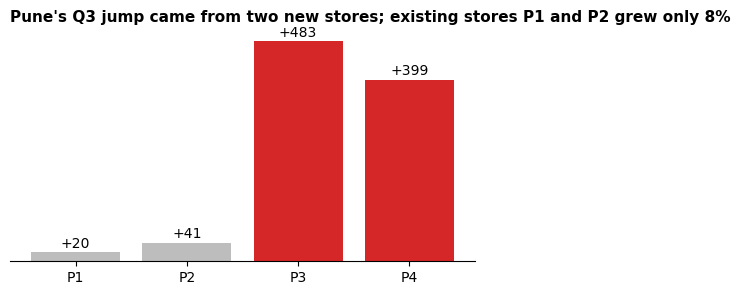

In [14]:
title = "Pune's Q3 jump came from two new stores; existing stores P1 and P2 grew only 8%"    # TODO: a one-sentence, takeaway title (state the finding, not just "Orders by store")

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [15]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = df.groupby(["zone", "delivery_partner"])["on_time"].mean().mul(100).round(1).unstack()
better_in_every_zone = 'Partner A'
phenomenon = "Simpson's paradox"

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.4,72.0
Urban,98.8,96.9


Better inside every zone: Partner A | effect: Simpson's paradox


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. (b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.

*Your answer:*

(a) "Pune orders rose 117% from Q2 to Q3 (803 → 1,746) mainly because two new stores, P3 and P4, opened in Q3 and added 882 orders. On a like-for-like basis, the two existing stores (P1, P2) grew +7.6% (803 → 864). The expansion added volume; whether it is a 'success' depends on the new stores' costs and profitability, which this data does not show."

(b) Partner B mostly delivers to Urban addresses (84% of its orders), where deliveries are short (about 1.8 km) and almost always on time. Partner A does most of the hard Suburban deliveries (67% of its orders, about 4.8 km). When you compare within the same zone, Partner A is better in both: Urban 98.8% vs 96.9%, Suburban 81.4% vs 72.0%. B's higher overall figure (93% vs 87%) comes from its easier mix of orders, not from better service. This is Simpson's paradox, and routing every order to B would likely lower on-time performance, especially in the suburbs. The careful human's question: "Are we comparing like with like? Is there a confounding variable (here, zone and distance) that differs between the groups and also drives the outcome?" A comparison should be checked within strata before anyone acts on it.

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [17]:
decisions = {
    1: "Accept",   # Bengaluru trend
    2: "Correct",   # average order value
    3: "Correct",   # Pune doubled
    4: "Reject",   # Hyderabad fell because service worsened
    5: "Reject",   # Partner B more punctual
    6: "Accept",   # delivery time vs rating
    7: "Accept",   # discount vs basket
    8: "Accept",   # suburban slower (check it yourself: df.groupby("zone")["delivery_minutes"].mean())
    9: "Reject",   # recovery prediction
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

print(df.groupby("zone")["delivery_minutes"].mean().round(1))
accepted = 4     # TODO: how many insights did you mark 'Accept'?
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

zone
Suburban    26.1
Urban       20.8
Name: delivery_minutes, dtype: float64
Accepted as stated: 4/9 | precision = 0.44 | recall = 0.57 | F1 = 0.50
Review effort spent on insights that were not fully correct: 56%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

*Your answer:* 
It is an assistant, not a replacement. Only 4 of its 9 insights were correct as stated (precision ≈ 0.44), it surfaced only 4 of the 7 true insights the expert team found (recall ≈ 0.57, F1 ≈ 0.50), and 56% of the review effort went into claims that needed correcting or rejecting. Worse, its errors were in the highest-stakes claims: the Hyderabad cause, routing every order to Partner B, and "Pune expansion is a huge success". Those would have led Meera to wrong operational decisions, so the AI is useful for quickly drafting candidate findings, but every claim needs human verification before it reaches leadership.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [18]:
levels = {
    2: "data",   # "The average order value is ₹465."
    6: "between",   # "Longer delivery times go with lower ratings."
    9: "beyond",   # "Orders will recover in October."
}      # TODO: use 'data', 'between' or 'beyond'
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [19]:
user_actions = {
    '"Never use pie charts in this report"': 'Constrain',           
    '"Use 5-minute bins for delivery time"': 'Adjust',          
    '"Focus on on-time rate by city"': 'Steer',                     
    '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',    
    '"Not this chart again"': 'Reject',
}   # TODO: replace None with one of 'Reject', 'Constrain', 'Steer', 'Adjust', 'Pin'
user_actions

{'"Never use pie charts in this report"': 'Constrain',
 '"Use 5-minute bins for delivery time"': 'Adjust',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [20]:
threat = 'wrong problem'   # TODO: 'wrong problem', 'wrong abstraction', 'wrong idiom' or 'wrong algorithm' (Munzner)
threat

'wrong problem'

**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

*Your answer:*

Insight 2 (rewritten): "From January to September, the median FreshKart order was ₹358: half of all orders were below that. The mean is ₹465 because a small number of very large orders pull it up, so the median is the better guide to a typical customer's basket. (Based on 13,917 orders after removing 70 duplicate rows.)"

Insight 4 (rewritten): "Hyderabad's recorded orders fell from 483 in August to 346 in September (−28%), but most of that drop is missing data: store H2 recorded no orders from about 7 to 24 September. For H1 and H3, which have complete data, orders fell 9.5% (326 → 295). On-time delivery in Hyderabad was steady (89.0% in August, 88.7% in September), and discounts were unchanged, so the data does not show worse service as the cause. We are confirming with the H2 team whether the store was closed or its order feed failed."


---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?

*Your reflection:* Insight 5 (Partner B is more punctual) was the most convincing at first. It came with two precise-looking percentages (93% vs 87%), the gap was large, and it ended in a clear, actionable recommendation, which made it sound like finished analysis. The numbers were in fact computed correctly, which is exactly why it was dangerous: nothing looked "wrong" until I split by zone and Partner A turned out to be better in both. Without the stratified check I would probably have accepted it, which is a clear example of automation bias: trusting a confident, specific output over looking for confounders myself.

**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?

*Your reflection:* I would let the AI work with little supervision on data profiling and alerting: counting duplicates, missing values and rows per store per week, and flagging anomalies such as H2's zero-order weeks. These checks are cheap, the AI only points to where to look, and a false alarm costs a few minutes of review. I would insist on a human check for causal explanations and operational recommendations, such as "service got worse" or "route all orders to Partner B". Those are high-stakes, hard to reverse once contracts or routing change, and their errors are invisible because the numbers look right. My criteria were stakes, reversibility, and whether an error would be obvious or silent.

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?

*Your reflection:* For the Hyderabad drop, the tool should have shown a data-completeness panel next to the claim: rows per store per week with a warning such as "H2: 0 rows in 2 of 4 September weeks", plus the code it used and a like-for-like figure for stores with complete data. It should also have labelled "because service got worse" as a hypothesis and shown the evidence for it (on-time % Aug vs Sep, which would have immediately contradicted it). As controls, I would want to exclude a store or date range and re-run instantly, edit the generated statement before it goes into the report, and switch off automatic causal explanations so the tool lists competing hypotheses instead.

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?

*Your reflection:* The AI cannot be held accountable, and the vendor is responsible only for the tool working as advertised. Since I signed off the report, I am accountable for the numbers, and Meera is accountable for the decisions she makes and presents from them. Next time I would keep a short verification log: for every number, the code cell that produced it, the row count and filters used, and any known caveats such as missing ratings or the H2 gap. I would also ask a colleague to independently reproduce the two or three highest-stakes figures. That way any remaining error can be traced and fixed quickly, and Meera knows exactly how confident she can be in each claim.